# Estado del arte: PD de vida completa por supervivencia, riesgos competitivos y satélites macroeconómicos

**Pregunta:** ¿Coinciden los tres modelos de PD de vida completa del producto con los métodos de supervivencia que recomienda la investigación, dónde subpredicen una cosecha de crisis, y qué cuesta en probabilidad de incumplimiento y en PCE tratar el prepago como censura y no como una salida competidora?

- **Nivel:** 3, Estado del arte
- **Requisitos previos:** los cuadernos 01 a 05 de este tema
- **Tiempo de lectura:** unos 55 minutos

## Objetivos

Al terminar este cuaderno puedes:

- ubicar los tres peldaños de PD de vida completa del C06 (Kaplan-Meier, una tasa de riesgo en tiempo discreto con covariables macro, un modelo de Cox) entre los métodos de supervivencia que encontró la investigación, y decir qué métodos no corre el producto;
- mostrar por qué el logit en tiempo discreto y el modelo de Cox dan coeficientes casi iguales cuando la tasa de riesgo por período es pequeño;
- verificar los signos de los coeficientes macro contra la expectativa económica, como debe hacerlo un validador, y leer qué hace un signo equivocado a la PCE de un escenario;
- comparar los tres peldaños sobre los mismos datos por discriminación, puntaje de Brier integrado y calibración de la PD acumulada, agrupada y para la cosecha de la crisis;
- medir lo que cuesta tratar el prepago como censura frente a una mirada de riesgos competitivos, y leer las trayectorias del factor del satélite macro con su reversión al largo plazo.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))
RUNGS = ("L0-km", "L1-dth", "L2-cox")
RUNG_NAME = {"L0-km": "Kaplan-Meier", "L1-dth": "logit de tiempo discreto", "L2-cox": "Cox"}
MACRO = {
    "unemployment_rate": "tasa de desempleo",
    "real_gdp_growth": "crecimiento del PIB real",
    "prime_rate": "tasa preferencial",
}
LIGHT = {"green": "verde", "amber": "ámbar", "red": "rojo"}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son el caso C06 a la fecha de reporte 2008-12-31: los préstamos 7(a) a pequeñas empresas de la SBA (Obras del Gobierno de EE. UU., clase de licencia `mirror-allowed`) y las formas de escenario 2026 de la Reserva Federal (mirror-allowed). Se leen dos archivos versionados.

- `data/derived/C06/models-rd-2008-12.json`: el ajuste de los tres peldaños (`fit.ladder`: los coeficientes y errores estándar, la línea base de los peldaños de Kaplan-Meier y de Cox), el escalador macro del peldaño de tasa de riesgo (`model[].details.macro_scaler`), la conversión de un factor (`fit.pit`: la historia del factor sistemático y el satélite) y las definiciones de escenario con sus trayectorias de factor (`fit.scenario_definitions`).
- `data/derived/C06/rd-2008-12.json`: `outputs.rung_comparison` (discriminación, puntaje de Brier integrado y diferencia de calibración a 12 meses de cada peldaño), y las filas de `tests` de la prueba retrospectiva de vida completa por cohorte de origen y peldaño, cuyos `extras` guardan la diferencia de cada horizonte.

Los tres peldaños los ajustó el flujo de cálculo (`data-flujo de cálculo/flujo de cálculo/cases/c06/ladder.py`, con `statsmodels`) sobre los préstamos conocidos a la fecha de reporte; el archivo crudo de préstamos no está versionado, así que este cuaderno **lee los ajustes y las pruebas, y no reajusta**. Todo lo que se recalcula abajo es aritmética sobre números versionados o una llamada al motor sobre ellos.

In [2]:
# Cargar el archivo de modelos y el artefacto de la fecha de reporte y listar los tres peldaños
from riskvalidation.provisions import ecl as ecl_engine, term_structure as tsm
from riskvalidation.validation import ifrs9

ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived" / "C06"
models = json.loads((DERIVED / "models-rd-2008-12.json").read_text(encoding="utf-8"))
case = json.loads((DERIVED / "rd-2008-12.json").read_text(encoding="utf-8"))
fit = models["fit"]
ladder = {r["rung_id"]: r for r in fit["ladder"]}
print("motor que calculó el artefacto:", case["provenance"]["riskvalidation_version"])
print("motor instalado ahora:", md.version("riskvalidation"))
for slot in models["model"]:
    loans, defaults = slot["parameters"]["n_loans"]["value"], slot["parameters"]["n_defaults"]["value"]
    print(f"{RUNG_NAME[slot['id']]:22s} | préstamos {int(loans)} | incumplimientos {int(defaults)}")

motor que calculó el artefacto: 1.0.1
motor instalado ahora: 1.0.1
Kaplan-Meier           | préstamos 871618 | incumplimientos 74139
logit de tiempo discreto | préstamos 871618 | incumplimientos 74139
Cox                    | préstamos 871618 | incumplimientos 74139


## Método

Los tres peldaños modelan el tiempo desde la fecha de reporte hasta el incumplimiento, con el prepago como censura, y dan la PD acumulada $F(t)$ que el cuaderno 01 convierte en una PCE. Difieren en cómo dejan que la tasa de riesgo dependa del préstamo y de la macroeconomía.

**L0, Kaplan-Meier.** Una curva agrupada por edad del préstamo. El estimador producto-límite de la supervivencia es $\hat S(t) = \prod_{t_i \le t}\bigl(1 - d_i/n_i\bigr)$, con $d_i$ los incumplimientos y $n_i$ los préstamos en riesgo a la edad $t_i$. No tiene covariables ni macroeconomía, así que su orden es solo el orden por edad.

**L1, tasa de riesgo en tiempo discreto con covariables macro.** Una regresión logística sobre registros préstamo-período (Shumway, 2001; Botha y Verster, 2025):

$$\mathrm{logit}\,h_i(t) = \alpha(a_{it}) + \boldsymbol\beta^\top \mathbf{x}_i + \boldsymbol\gamma^\top \mathbf{m}_{t-\ell}$$

con $\alpha$ una función escalonada de la edad del préstamo (bandas de edad), $\mathbf{x}_i$ las covariables del préstamo (tamaño, plazo, sector, rotativo) y $\mathbf{m}_{t-\ell}$ las variables macro rezagadas $\ell = 1$ trimestre, estandarizadas. Es el peldaño que lleva los escenarios.

**L2, riesgos proporcionales de Cox** (Cox, 1972): $h_i(t) = h_0(t)\exp(\boldsymbol\beta^\top \mathbf{x}_i)$, con la edad del préstamo como escala de tiempo y empates de Breslow. La implementación de `statsmodels` que usa el flujo de cálculo no tiene covariables que varíen en el tiempo, así que este peldaño **no tiene macroeconomía** y no puede llevar un escenario.

Para una tasa de riesgo por período pequeño $h$, $\mathrm{logit}\,h = \log\bigl(h/(1-h)\bigr) \approx \log h$, así que los coeficientes de L1 y L2 en las covariables comunes deberían coincidir. La macroeconomía entra a la estructura de plazos solo en L1.

**La validación de un peldaño** es la prueba retrospectiva de vida completa del cuaderno 05 y la comparación de peldaños: la concordancia de Harrell (la probabilidad de que, de dos préstamos, el de menor supervivencia tenga el mayor riesgo previsto, con empates como un medio), el puntaje de Brier integrado de la predicción de supervivencia y la diferencia de calibración a 12 meses entre la PD acumulada prevista y la observada. La mirada de un factor (BCBS 2005; Gordy 2003) vincula la macroeconomía con la PD mediante un factor sistemático $z$ que un satélite regresa sobre variables macro; los pesos de los pronósticos de corto plazo decaen hacia valores de largo plazo (carta del BCE del 1 de abril de 2020).

## Estado del arte

La investigación (dossiers 02 y 04) encontró los métodos siguientes para la estructura de plazos del incumplimiento bajo IFRS 9. La última columna dice qué hace el producto con cada uno.

| Método | Qué agrega | Fuente | En Contraste |
|---|---|---|---|
| Kaplan-Meier y curvas de cosecha | el incumplimiento acumulado agrupado y por cohorte, con censura | Botha y Verster 2025 | peldaño L0, leído aquí |
| Tasa de riesgo en tiempo discreto (logit persona-período) con covariables macro | PD de vida completa bajo un escenario macro, con un vector macro rezagado | Shumway 2001; Botha y Verster 2025 | peldaño L1, leído aquí |
| Riesgos proporcionales de Cox, con o sin covariables que varían en el tiempo | efectos de covariables sin supuesto de línea base; macro que varía en el tiempo | Cox 1972 | peldaño L2 (sin covariables que varíen en el tiempo), leído aquí |
| Riesgos competitivos, por causa o Fine-Gray | incidencia de incumplimiento cuando el prepago es una salida competitiva | Fine y Gray 1999; Botha y Verster 2025 | `competing_risks` del motor; el C06 trata el prepago como censura (hallazgo `F-PREPAYMENT`) |
| Descomposición edad-período-cohorte | ciclo de vida, calidad de la cosecha y entorno en un solo logit | Breeden 2016 | no se corre |
| Modelos multiestado y de tasas de transición | transiciones entre estados de mora con insumos macro | Botha, Verster y Breedt 2025 | no se corre |
| Mixture cure, bosques de supervivencia, supervivencia profunda | una fracción curada; efectos no lineales | la investigación, dossier 04 (peldaños S4 a S6) | no se corre |
| Satélite macro con reversión a la media | trayectorias de escenario de un factor sistemático que revierten al largo plazo | carta del BCE del 1 de abril de 2020; Botha y Verster 2025 | el satélite de un factor de `fit.pit`, leído aquí |

Los paquetes que necesitan esos últimos peldaños (`lifelines`, `scikit-survival`, `pycox`) no son pines del flujo de cálculo ni del entorno de cuadernos, así que **NO ESTÁ VERIFICADO** que Contraste corra alguno: este cuaderno compara solo los tres peldaños que el C06 versionó. Las métricas de validación de la investigación para modelos de supervivencia (concordancia de Harrell y de Uno, AUC dependiente del tiempo, puntaje de Brier integrado, y calibración de la PD acumulada por decil en horizontes fijos contra el estimador de Kaplan-Meier o de Aalen-Johansen) son las que usa la comparación de peldaños; la comparación versionada reporta la concordancia, el puntaje de Brier integrado y la diferencia de calibración a 12 meses.

### Paso 1: los coeficientes del logit y del modelo de Cox en las covariables comunes

Ambos peldaños tienen las covariables del préstamo: tres tramos de tamaño, tres de plazo, once grupos de sector y la marca de rotativo. La celda alinea los 18 coeficientes que comparten el logit de tiempo discreto y el modelo de Cox y mide cuán lejos están, en términos absolutos, como correlación y en errores estándar del logit. La figura grafica el coeficiente de Cox de cada covariable contra su coeficiente del logit; si los dos métodos coincidieran exactamente, todos los puntos quedarían sobre la diagonal.

covariables comunes: 18 | solo en el peldaño de tiempo discreto: 12
mayor diferencia absoluta: 0.0389
correlación: 0.9998
mayor diferencia en errores estándar del logit: 3.2


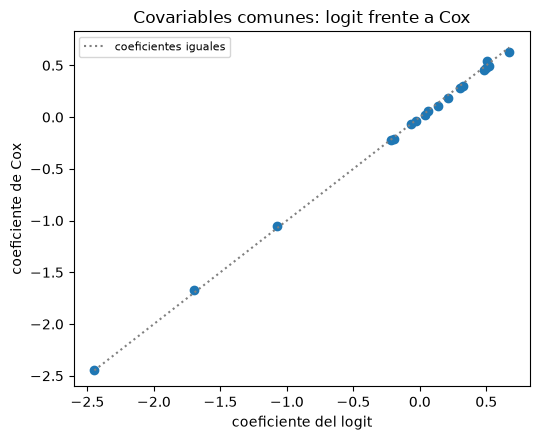

In [3]:
# Alinear los coeficientes que comparten el logit de tiempo discreto y el modelo de Cox y compararlos
dth = {c["name"]: c for c in ladder["L1-dth"]["coefficients"]}
cox = {c["name"]: c for c in ladder["L2-cox"]["coefficients"]}
common = [name for name in cox if name in dth]
logit_values = np.array([dth[n]["estimate"] for n in common])
cox_values = np.array([cox[n]["estimate"] for n in common])
std_errors = np.array([dth[n]["std_error"] for n in common])
print("covariables comunes:", len(common), "| solo en el peldaño de tiempo discreto:", len(dth) - len(common))
print("mayor diferencia absoluta:", round(float(np.abs(logit_values - cox_values).max()), 4))
print("correlación:", round(float(np.corrcoef(logit_values, cox_values)[0, 1]), 5))
print("mayor diferencia en errores estándar del logit:",
      round(float(np.max(np.abs(logit_values - cox_values) / std_errors)), 2))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.scatter(logit_values, cox_values, color="tab:blue")
span = [logit_values.min(), logit_values.max()]
ax.plot(span, span, color="grey", linestyle=":", label="coeficientes iguales")
ax.set_xlabel("coeficiente del logit")
ax.set_ylabel("coeficiente de Cox")
ax.set_title("Covariables comunes: logit frente a Cox")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Los 18 coeficientes compartidos quedan casi sobre la diagonal: su correlación es 0,9998 y la mayor diferencia absoluta es 0,0389, que son 3,2 errores estándar del logit. La coincidencia es esperable. Para una tasa de riesgo $h$ por período pequeña el logit $\log\bigl(h/(1-h)\bigr)$ es cercano a $\log h$, que es la escala del modelo de Cox, de modo que los dos métodos estiman casi los mismos efectos de las covariables. Los puntos que se alejan de la diagonal pertenecen a las covariables con mayor tasa de riesgo por período, donde la aproximación es peor. La elección entre los dos no trata entonces de las covariables del préstamo sino de lo que cada uno puede llevar: solo el logit puede tomar la macroeconomía.

### Paso 2: los coeficientes macro y sus signos

Solo el peldaño logit tiene covariables macro, estandarizadas con una media y una desviación estándar. Un validador verifica cada signo frente a la expectativa económica antes de leer nada más: una mayor tasa de desempleo y una mayor tasa preferencial deberían subir la tasa de riesgo de incumplimiento, y un mayor crecimiento del PIB real debería bajarla. La expectativa es un insumo declarado de la lección. La celda imprime cada estimación con su error estándar, su estadístico z y su razón de riesgo por desviación estándar, y si el signo es el esperado.

In [4]:
# Leer los coeficientes macro del peldaño logit y verificar sus signos frente a la expectativa declarada
EXPECTED_SIGN = {"unemployment_rate": +1, "real_gdp_growth": -1, "prime_rate": +1}  # lesson input
for name, sign in EXPECTED_SIGN.items():
    c = dth[name]
    z = c["estimate"] / c["std_error"]
    matches = "sí" if np.sign(c["estimate"]) == sign else "no"
    print(f"{MACRO[name]:26s} | estimación {c['estimate']:+.4f} | error estándar {c['std_error']:.4f}")
    print(f"{'':26s} | z {z:+.2f} | razón de riesgo {np.exp(c['estimate']):.3f} | signo esperado: {matches}")

tasa de desempleo          | estimación -0.0534 | error estándar 0.0089
                           | z -5.99 | razón de riesgo 0.948 | signo esperado: no
crecimiento del PIB real   | estimación -0.1920 | error estándar 0.0039
                           | z -49.11 | razón de riesgo 0.825 | signo esperado: sí
tasa preferencial          | estimación +0.1138 | error estándar 0.0060
                           | z +18.86 | razón de riesgo 1.120 | signo esperado: sí


El crecimiento del PIB real baja la tasa de riesgo como se espera, con una estimación de -0,1920, un z de -49,11 y una razón de riesgo de 0,825 por desviación estándar, y la tasa preferencial la sube, +0,1138 con una razón de 1,120. La tasa de desempleo tiene el signo equivocado: su estimación es -0,0534, con un z de -5,99, de modo que un mayor desempleo baja la tasa de riesgo y el coeficiente es estadísticamente distinto de cero. Es la sensibilidad que el hallazgo versionado `F-SCENARIO-ORDER` culpa de que el escenario severamente adverso dé una PCE menor que el base en el cuaderno 03. Un validador rechaza un coeficiente macro de signo equivocado aunque sea significativo, porque un efecto significativo que se mueve contra la economía puede señalar colinealidad entre las variables macro en una historia corta, lo que este cuaderno no prueba.

### Paso 3: los tres peldaños sobre los mismos datos, puntuados por el motor

Las filas de la prueba retrospectiva guardan, para cada peldaño y cohorte de originación, la brecha con signo entre la PD acumulada observada y la predicha en cada horizonte, definida como observada menos predicha. La celda recupera la curva predicha de cada peldaño desde la observada y la brecha, y entrega las tres curvas predichas a `lifetime_pd_backtest` del motor, que devuelve la mayor brecha, la mayor brecha relativa y una luz. Lo hace para la cohorte agrupada `all` y para la cosecha 2007, los préstamos originados justo antes de la crisis.

In [5]:
# Puntuar cada peldaño en dos cohortes con la prueba de vida completa del motor
rows = case["outputs"]["lifetime_backtest"]["rows"]
lifetime_rows = [t for t in case["tests"] if t["test_id"] == "ifrs9.lifetime_pd_backtest"]
tests = {(t["model_id"], t["segment"]): t for t in lifetime_rows}
curves = {}
for cohort in ("all", "2007"):
    cohort_rows = [r for r in rows if r["origination_cohort"] == cohort]
    months = np.array([r["months"] for r in cohort_rows])
    obs = np.array([r["observed_cumulative_pd"] for r in cohort_rows])
    curves[cohort] = (months, obs, {})
    for rung in RUNGS:
        row = tests[(rung, cohort)]
        predicted = obs - np.array(row["extras"]["signed_gap"])
        curves[cohort][2][rung] = predicted
        at_risk = np.full(months.size, row["n"], dtype=float)
        events = np.full(months.size, row["n_events"], dtype=float)
        score = ifrs9.lifetime_pd_backtest(months, predicted, obs, at_risk, events, model_id=rung, segment=cohort)
        relative = max(score.extras["relative_gap"])
        print("cohorte", "agrupada" if cohort == "all" else cohort, "|", RUNG_NAME[rung])
        print(f"   mayor brecha {score.metric:.4f} | mayor brecha relativa {relative:.4f}")
        print("   luz sin la correlación:", LIGHT[score.light.value])

cohorte agrupada | Kaplan-Meier
   mayor brecha 0.0427 | mayor brecha relativa 0.9147
   luz sin la correlación: rojo
cohorte agrupada | logit de tiempo discreto
   mayor brecha 0.0167 | mayor brecha relativa 0.3228
   luz sin la correlación: ámbar
cohorte agrupada | Cox
   mayor brecha 0.0427 | mayor brecha relativa 1.0791
   luz sin la correlación: rojo
cohorte 2007 | Kaplan-Meier
   mayor brecha 0.1240 | mayor brecha relativa 3.1225
   luz sin la correlación: rojo
cohorte 2007 | logit de tiempo discreto
   mayor brecha 0.0859 | mayor brecha relativa 1.2625
   luz sin la correlación: rojo
cohorte 2007 | Cox
   mayor brecha 0.1163 | mayor brecha relativa 3.2459
   luz sin la correlación: rojo


La prueba de vida completa del motor, llamada sin la correlación de activos, lee la brecha relativa y no la banda de Vasicek del cuaderno 05, de modo que estas luces son más estrictas que las versionadas. En la cohorte agrupada el logit de tiempo discreto tiene la menor de las mayores brechas, 0,0167 con una brecha relativa de 0,3228 y una luz ámbar, mientras que los peldaños de Kaplan-Meier y de Cox tienen 0,0427 y brechas relativas de 0,9147 y 1,0791, rojas. En la cosecha 2007 las tres brechas son 0,1240, 0,0859 y 0,1163 y las tres son rojas, con brechas relativas sobre 1. El orden de los peldaños no cambia entre las cohortes, con el logit primero, pero incluso el mejor peldaño está lejos del resultado de la cosecha que enfrentó la crisis.

### Paso 3b: la cosecha 2007 dibujada

La cosecha 2007 es la prueba de esfuerzo de una PD de vida completa: préstamos otorgados en la cima del ciclo que luego pasaron por la crisis. La figura dibuja el incumplimiento acumulado observado para esa cosecha con el estimador de Kaplan-Meier, y la curva que predijo cada uno de los tres peldaños, en los seis horizontes.

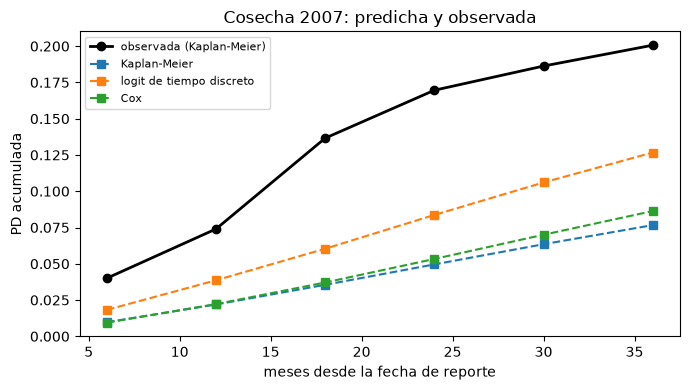

In [6]:
# Dibujar la cosecha 2007: el incumplimiento acumulado observado y la curva que predijo cada peldaño
months7, obs7, predicted7 = curves["2007"]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(months7, obs7, color="black", marker="o", linewidth=2, label="observada (Kaplan-Meier)")
for rung, color in zip(RUNGS, ("tab:blue", "tab:orange", "tab:green")):
    ax.plot(months7, predicted7[rung], color=color, marker="s", linestyle="--", label=RUNG_NAME[rung])
ax.set_xlabel("meses desde la fecha de reporte")
ax.set_ylabel("PD acumulada")
ax.set_title("Cosecha 2007: predicha y observada")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

La curva observada de la cosecha 2007 sube a cerca de 0,20 a los 36 meses, y las tres predicciones quedan bajo ella en todos los horizontes: el peldaño de Kaplan-Meier llega a 0,0766 a los 36 meses, el de Cox a 0,0863 y el logit a 0,1267. El logit es el más cercano porque sus covariables macro suben la tasa de riesgo en los trimestres de crisis, y aun así cubre poco más de la mitad del incumplimiento realizado. Las curvas de Kaplan-Meier y de Cox son ciegas a la macroeconomía y a la cosecha, de modo que describen un préstamo promedio de la cartera y no ven los préstamos otorgados en la cima del ciclo. Las covariables macro acortan la brecha y no la cierran.

### Paso 4: lo que cuesta en PCE la elección del peldaño

Una PD de vida completa importa a través de la PCE. La celda valora una cuenta declarada, una exposición de 100.000 USD al 8% anual con la pérdida dado el incumplimiento del segmento de préstamos de más de 20 años, a un horizonte de 36 meses con cuatro curvas: la observada y la curva predicha de cada peldaño para la cohorte agrupada. Cada curva pasa por `from_cumulative` para obtener su PD marginal, y `ecl_scenario` la convierte en dinero. La exposición y la tasa son insumos de la lección, y la figura se deja a los números.

In [7]:
# Valorar la cuenta declarada a 36 meses con la curva predicha de cada peldaño y con la observada
months_all, obs_all, predicted_all = curves["all"]
LGD = {s["segment_id"]: s["lgd"] for s in fit["lgd"]["segments"]}["term-gt-240"]
EAD, EIR = 100_000.0, np.array([0.08])  # stated inputs of the lesson
priced = {}
for label, curve in (("observada", obs_all), *[(RUNG_NAME[r], predicted_all[r]) for r in RUNGS]):
    structure = tsm.from_cumulative(curve, months_all)
    marginal = structure.marginal[None, :]
    priced[label] = float(ecl_engine.ecl_scenario(marginal, LGD, EAD, EIR, months_all, 36)[0])
reference = priced["observada"]
for label, value in priced.items():
    print(f"{label:24s} | PCE a 36 meses, USD {value:9.2f} | sobre la observada {value / reference:6.3f}")

observada                | PCE a 36 meses, USD   5175.62 | sobre la observada  1.000
Kaplan-Meier             | PCE a 36 meses, USD   3114.33 | sobre la observada  0.602
logit de tiempo discreto | PCE a 36 meses, USD   4548.98 | sobre la observada  0.879
Cox                      | PCE a 36 meses, USD   3095.79 | sobre la observada  0.598


La elección del peldaño es una elección sobre dinero. Valorada con el incumplimiento acumulado observado de la cohorte agrupada, que es lo que ocurrió y no un pronóstico, la cuenta declarada habría costado 5.175,62 USD de PCE a 36 meses. La curva del logit da 4.548,98 USD, 0,879 de eso, y las curvas de Kaplan-Meier y de Cox dan 3.114,33 y 3.095,79 USD, cerca de 0,60 de eso. Un banco que hubiera provisionado con cualquiera de los peldaños ciegos a la macroeconomía habría mantenido 40% menos que el resultado, e incluso el logit queda 12% corto. La cohorte agrupada incluye la crisis, que es la razón de que todo peldaño subpredice, y el orden es el mismo que en la prueba retrospectiva.

### Paso 5: el prepago como censura frente a una salida competidora

C06 trata el prepago como censura (hallazgo `F-PREPAYMENT`): la tasa de riesgo de incumplimiento por causa es toda la PD de vida completa. La investigación recomienda una vista de riesgos competidores, en que un préstamo que se paga ya no puede incumplir (Fine y Gray, 1999; Botha y Verster, 2025). La celda toma la curva de Kaplan-Meier, recupera su tasa de riesgo con `from_cumulative`, agrega una tasa de riesgo de prepago declarada de 0, 0,5%, 1% y 2% por trimestre con `competing_risks`, y valora la PCE de vida completa de la cuenta declarada del paso 4 bajo cada incidencia de incumplimiento. La figura dibuja las curvas de incidencia.

tasa de riesgo de prepago por trimestre 0.0
   incidencia de incumplimiento a 36 meses: 0.04394
   PCE de vida completa, USD: 5915.44
   censura sobre competidora: 1.0
tasa de riesgo de prepago por trimestre 0.005
   incidencia de incumplimiento a 36 meses: 0.04222
   PCE de vida completa, USD: 5453.55
   censura sobre competidora: 1.0847
tasa de riesgo de prepago por trimestre 0.01
   incidencia de incumplimiento a 36 meses: 0.04056
   PCE de vida completa, USD: 5034.42
   censura sobre competidora: 1.175
tasa de riesgo de prepago por trimestre 0.02
   incidencia de incumplimiento a 36 meses: 0.03744
   PCE de vida completa, USD: 4306.99
   censura sobre competidora: 1.3734


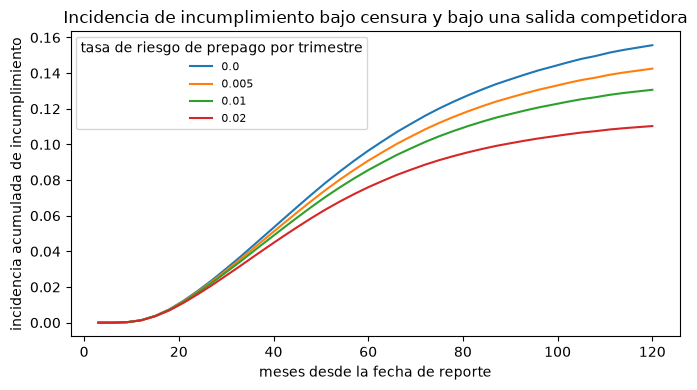

In [8]:
# Agregar una tasa de riesgo de prepago declarada a la curva de Kaplan-Meier y comparar incidencia y PCE
km = ladder["L0-km"]["baseline"]
km_months = np.array(km["months"])
single = tsm.from_cumulative(np.array(km["cumulative_pd"]), km_months)
at_36 = int(np.flatnonzero(km_months == 36)[0])
incidence, ecl_life = {}, {}
for prepay in (0.0, 0.005, 0.01, 0.02):
    competing = tsm.competing_risks(single.hazard, np.full(single.hazard.shape, prepay), km_months)
    incidence[prepay] = competing.cumulative_default
    marginal = competing.marginal_default[None, :]
    ecl_life[prepay] = float(ecl_engine.ecl_scenario(marginal, LGD, EAD, EIR, km_months, int(km_months[-1]))[0])
    print("tasa de riesgo de prepago por trimestre", prepay)
    print("   incidencia de incumplimiento a 36 meses:", round(float(incidence[prepay][at_36]), 5))
    print("   PCE de vida completa, USD:", round(ecl_life[prepay], 2))
    print("   censura sobre competidora:", round(ecl_life[0.0] / ecl_life[prepay], 4))

fig, ax = plt.subplots(figsize=(7, 4))
for prepay, curve in incidence.items():
    ax.plot(km_months, curve, label=f"{prepay}")
ax.set_xlabel("meses desde la fecha de reporte")
ax.set_ylabel("incidencia acumulada de incumplimiento")
ax.set_title("Incidencia de incumplimiento bajo censura y bajo una salida competidora")
ax.legend(title="tasa de riesgo de prepago por trimestre", fontsize=8)
fig.tight_layout()
plt.show()

Agregar una salida por prepago baja la incidencia de incumplimiento, y la vista de censura la sobrestima. Con una tasa de riesgo de prepago declarada de 0,5%, 1% y 2% por trimestre el incumplimiento acumulado a 36 meses baja de 0,04394 a 0,04222, 0,04056 y 0,03744, y la PCE de vida completa de la cuenta declarada baja de 5.915,44 USD a 5.453,55, 5.034,42 y 4.306,99. La razón entre la PCE con censura y la competidora es 1,0847, 1,175 y 1,3734. Las curvas se separan más cuanto más largo es el horizonte, de modo que la elección importa más para los préstamos largos de la cartera. Las tasas de riesgo de prepago son insumos de la lección y no estimaciones, así que el resultado es una sensibilidad: el lado prudente de la vista de censura tiene un precio que crece con el prepago.

### Paso 6: el satélite y la historia del factor

La conversión de un factor da el factor sistemático $z$ de cada trimestre pasado desde la tasa de incumplimiento realizada de la cartera (`fit.pit.z_hat`), y un satélite regresa ese factor sobre las variables macro de modo que un escenario se pueda convertir en una trayectoria de $z$. La celda imprime los coeficientes del satélite con el signo que debería tener el factor, y convierte la historia de 63 trimestres del factor de vuelta en la tasa de incumplimiento que implica con `ttc_to_pit`, usando la PD a través del ciclo de la cartera y su correlación. La figura dibuja el factor y la tasa de incumplimiento que implica.

intercepto del satélite y término autorregresivo: 13.3395 0.0
tasa de desempleo          | coeficiente -1.0554 | signo esperado para el factor: sí
crecimiento del PIB real   | coeficiente +0.3289 | signo esperado para el factor: sí
tasa preferencial          | coeficiente -1.4056 | signo esperado para el factor: sí
trimestres de historia del factor: 63
media y desviación estándar del factor:
-0.15 0.731
último valor del factor: -1.8
tasa de incumplimiento implicada, menor y mayor:
0.003 0.0671


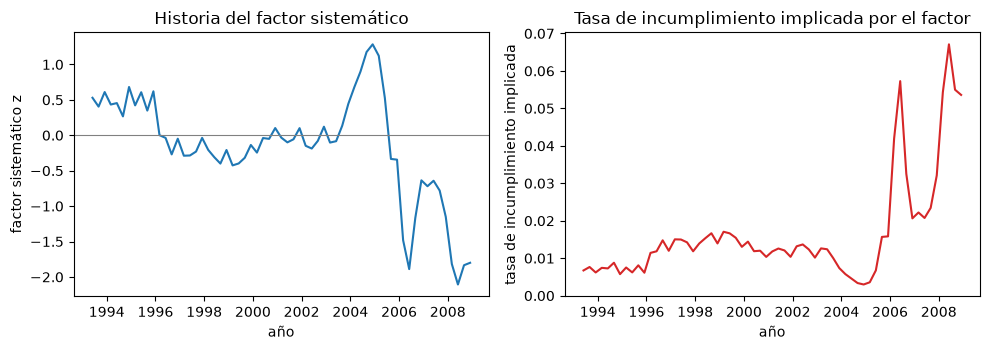

In [9]:
# Leer el satélite y la historia del factor, y convertir la historia en las tasas de incumplimiento que implica
pit = fit["pit"]
satellite = pit["satellite"]
params = case["outputs"]["non_linearity"]["parameters"]
EXPECTED_FACTOR_SIGN = {"unemployment_rate": -1, "real_gdp_growth": +1, "prime_rate": -1}  # stated expectation
print("intercepto del satélite y término autorregresivo:", round(satellite["intercept"], 4), satellite["ar1"])
for c in satellite["coefficients"]:
    sign_ok = "sí" if np.sign(c["value"]) == EXPECTED_FACTOR_SIGN[c["name"]] else "no"
    print(f"{MACRO[c['name']]:26s} | coeficiente {c['value']:+.4f} | signo esperado para el factor: {sign_ok}")
history = np.array([p["z"] for p in pit["z_hat"]])
years = [int(p["period"][:4]) + (int(p["period"][5:7]) - 1) / 12 for p in pit["z_hat"]]
implied = tsm.ttc_to_pit(np.full(history.size, params["pd_ttc"]), pit["rho"], history)
print("trimestres de historia del factor:", history.size)
print("media y desviación estándar del factor:")
print(round(float(history.mean()), 3), round(float(history.std()), 3))
print("último valor del factor:", round(float(history[-1]), 3))
print("tasa de incumplimiento implicada, menor y mayor:")
print(round(float(implied.min()), 4), round(float(implied.max()), 4))

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6))
left.plot(years, history, color="tab:blue")
left.axhline(0.0, color="grey", linewidth=0.8)
left.set_xlabel("año")
left.set_ylabel("factor sistemático z")
left.set_title("Historia del factor sistemático")
right.plot(years, implied, color="tab:red")
right.set_xlabel("año")
right.set_ylabel("tasa de incumplimiento implicada")
right.set_title("Tasa de incumplimiento implicada por el factor")
fig.tight_layout()
plt.show()

El satélite tiene los signos esperados: el factor cae con la tasa de desempleo (-1,0554) y la tasa preferencial (-1,4056) y sube con el crecimiento (+0,3289). La historia de 63 trimestres tiene una media de -0,15 y una desviación estándar de 0,731 y termina en -1,80, la crisis. Convertido de vuelta, el factor implica una tasa de incumplimiento entre 0,30% y 6,71%, un rango de más de veinte veces, que es el ciclo que debe llevar la estructura de plazos. Hay un desacuerdo entre las dos capas: en el modelo de tasa de riesgo la tasa de desempleo baja la PD, mientras que en el satélite baja el factor, lo que sube la PD. El archivo no dice por qué, y un validador lo lee como un hallazgo del modelo.

### Paso 7: las trayectorias de escenario del factor, convertidas en tasas de incumplimiento

El artefacto guarda tres trayectorias de escenario del factor, una por escenario macroeconómico, a lo largo de 120 meses. La celda convierte cada trayectoria en una trayectoria de tasas de incumplimiento condicionales con `ttc_to_pit`, pondera los tres escenarios en cada fecha con `weighted_pit_pd` y las ponderaciones de escenario versionadas, y compara la tasa ponderada con la tasa en el factor medio ponderado, la cantidad que el cuaderno 03 mostró demasiado baja. La figura dibuja las trayectorias del factor a la izquierda y las trayectorias de tasa de incumplimiento con las dos medidas ponderadas a la derecha.

mismo inicio en los tres escenarios: [-1.432 -1.432 -1.432]
factor al final de la trayectoria: [0.879 0.879 0.879]
mes 42 | z: [-1.205 -1.035 -0.956]
tasa de incumplimiento ponderada: 0.03162
tasa de incumplimiento en el factor medio: 0.03153


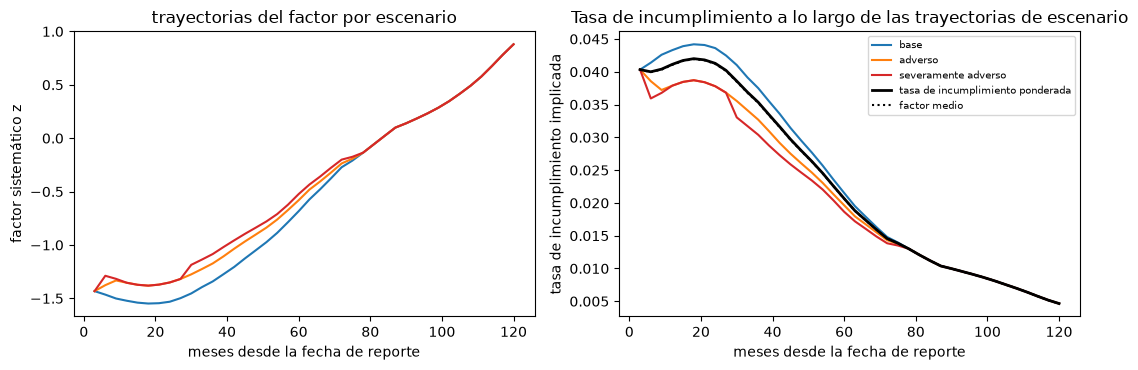

In [10]:
# Convertir las trayectorias del factor en trayectorias de tasa de incumplimiento y ponderarlas con el motor
definitions = fit["scenario_definitions"]
months_path = [p["months"] for p in definitions[0]["z_path"]]
z_paths = np.array([[p["z"] for p in d["z_path"]] for d in definitions])
weights = np.array([d["weight"] for d in definitions])
rate_paths = np.array([tsm.ttc_to_pit(np.full(z.size, params["pd_ttc"]), pit["rho"], z) for z in z_paths])
pd_ttc, rho = params["pd_ttc"], pit["rho"]
weighted = np.array([tsm.weighted_pit_pd(pd_ttc, rho, z_paths[:, t], weights) for t in range(len(months_path))])
at_mean = tsm.ttc_to_pit(np.full(len(months_path), params["pd_ttc"]), pit["rho"], weights @ z_paths)
print("mismo inicio en los tres escenarios:", np.round(z_paths[:, 0], 3))
print("factor al final de la trayectoria:", np.round(z_paths[:, -1], 3))
k = months_path.index(42)
print("mes", 42, "| z:", np.round(z_paths[:, k], 3))
print("tasa de incumplimiento ponderada:", round(float(weighted[k]), 5))
print("tasa de incumplimiento en el factor medio:", round(float(at_mean[k]), 5))

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8))
names = ("base", "adverso", "severamente adverso")
for z, rate, name, color in zip(z_paths, rate_paths, names, ("tab:blue", "tab:orange", "tab:red")):
    left.plot(months_path, z, color=color, label=name)
    right.plot(months_path, rate, color=color, label=name)
right.plot(months_path, weighted, color="black", linewidth=2, label="tasa de incumplimiento ponderada")
right.plot(months_path, at_mean, color="black", linestyle=":", label="factor medio")
left.set_xlabel("meses desde la fecha de reporte")
left.set_ylabel("factor sistemático z")
left.set_title("trayectorias del factor por escenario")
right.set_xlabel("meses desde la fecha de reporte")
right.set_ylabel("tasa de incumplimiento implicada")
right.set_title("Tasa de incumplimiento a lo largo de las trayectorias de escenario")
right.legend(fontsize=7)
fig.tight_layout()
plt.show()

Las tres trayectorias de escenario parten en -1,432 y terminan en +0,879, que es la reversión al largo plazo que pide la carta del BCE de 2020: el peso del pronóstico de corto plazo decae. En el medio el escenario base es la trayectoria más baja, -1,205 en el mes 42, frente a -1,035 del adverso y -0,956 del severamente adverso, lo contrario del orden esperado de severidad, y un factor más bajo es un año peor. A la derecha, la tasa de incumplimiento ponderada en el mes 42 es 0,03162 frente a 0,03153 en el factor medio, 0,3% mayor, la pequeña no linealidad a nivel de PD del cuaderno 03. El orden invertido es culpa de la capa macro y aparece en el factor antes de llegar a cualquier PCE.

## Resultados

**Respuesta:** Los tres peldaños del producto son los métodos de supervivencia más simples que lista la investigación (Kaplan-Meier, un logit de tiempo discreto con covariables macro y un modelo de Cox), y los tres subpredicen la cosecha de crisis: para la cohorte 2007 la mayor brecha entre la PD acumulada predicha y la observada es 0,1240, 0,0859 y 0,1163, y en la cartera agrupada el logit valora la PCE a 36 meses de la cuenta declarada en 4.548,98 USD frente a 5.175,62 sobre la curva observada (0,879) mientras que los otros dos alcanzan cerca de 0,60; tratar el prepago como censura en vez de salida competidora da una PCE de vida completa que es 1,0847, 1,175 y 1,3734 veces la competidora para tasas de riesgo de prepago de 0,5%, 1% y 2% por trimestre.

- **El logit y el modelo de Cox coinciden de cerca, no idénticamente.** En las 18 covariables compartidas la correlación de los coeficientes es 0,9998 y la mayor diferencia absoluta es 0,0389, que son 3,2 errores estándar del logit; las dos escalas difieren más donde la tasa de riesgo por período es mayor, como dice la aproximación $\mathrm{logit}\,h \approx \log h$.
- **Un signo macro es equivocado.** El crecimiento del PIB real baja la tasa de riesgo como se espera (-0,1920, una razón de riesgo de 0,825) y la tasa preferencial la sube (+0,1138, 1,120). La tasa de desempleo la baja (-0,0534, 0,948), lo contrario del signo esperado y estadísticamente distinta de cero. Es la sensibilidad que el hallazgo versionado `F-SCENARIO-ORDER` culpa del orden invertido de los escenarios.
- **La prueba de vida completa del motor ordena los peldaños igual en ambas cohortes.** El logit tiene la menor brecha (0,0167 agrupada, 0,0859 en 2007) y los peldaños de Kaplan-Meier y de Cox 0,0427 y 0,1240, y 0,0427 y 0,1163. Las luces de brecha relativa son rojas para todos los peldaños en la cosecha 2007.
- **La elección del peldaño tiene un precio en PCE.** La curva observada valora la cuenta declarada en 5.175,62 USD a 36 meses, el logit en 4.548,98 y las curvas de Kaplan-Meier y de Cox en 3.114,33 y 3.095,79.
- **Censura frente a salida competidora.** La curva de Kaplan-Meier da un incumplimiento acumulado de 0,04394 a 36 meses; con tasas de riesgo de prepago de 0,5%, 1% y 2% por trimestre la incidencia es 0,04222, 0,04056 y 0,03744 y la PCE de vida completa 5.453,55, 5.034,42 y 4.306,99 USD frente a 5.915,44 con censura.
- **El satélite tiene los signos esperados, las trayectorias revierten y el orden está invertido.** El factor cae con el desempleo (-1,0554) y la tasa preferencial (-1,4056) y sube con el crecimiento (+0,3289). Las tres trayectorias de escenario parten en -1,432 y terminan en +0,879. En el mes 42 el escenario base está bajo el adverso y el severamente adverso (-1,205, -1,035 y -0,956), lo contrario del orden esperado de severidad.

Lo que este cuaderno no muestra: lee los ajustes y no los reajusta, porque el archivo crudo de préstamos no está versionado. Los métodos de mezcla con curados, bosques de supervivencia, supervivencia profunda, edad-período-cohorte y multiestado del estado del arte no los corre el producto, y si hay un paquete disponible para ellos es NO VERIFICADO. Las tasas de riesgo de prepago, la exposición y la tasa son insumos de la lección, no estimaciones, y los resultados observados son castigos de préstamos de la SBA.

## Resumen

- Los tres peldaños de C06 son los métodos de supervivencia que la investigación recomienda en su versión más simple: la curva de Kaplan-Meier, un logit de tiempo discreto con covariables macro y un modelo de Cox sin covariables que varían en el tiempo; los métodos de mezcla con curados, bosques, profundos y multiestado no se corren.
- Los coeficientes del logit y de Cox coinciden de cerca en las covariables comunes, porque la tasa de riesgo por período es pequeña.
- La capa macro es donde los peldaños difieren y donde el modelo falla la verificación de signo de un validador: el desempleo tiene el signo equivocado en la tasa de riesgo, lo que invierte el orden de los escenarios.
- El peldaño logit gana la prueba de vida completa del motor y la valoración de la cuenta declarada, pero todo peldaño subpredice la PD acumulada en todos los horizontes, y la cosecha de crisis más que ninguna.
- Tratar el prepago como censura sobrestima la incidencia de incumplimiento de vida completa y la PCE, más cuanto más largo es el horizonte; las trayectorias macro revierten al largo plazo como pide la carta del BCE.

**Qué probar después.** Cambia `EXPECTED_SIGN` y mira qué coeficientes fallan; agrega una tasa de riesgo de prepago de 3% a la celda de riesgos competidores; lee las mismas tablas en el archivo `models-rd-2020-06.json` y compara los signos. Luego sigue con el cuaderno 08, que demuestra la afirmación de este tema.

## Referencias

- Botha, A. y Verster, T. (2025), Approaches for modelling the term-structure of default risk under IFRS 9: a tutorial using discrete-time survival analysis, ecuaciones 6 a 10. https://arxiv.org/abs/2507.15441
- Botha, A., Verster, T. y Breedt, R. (2025), Modelling the term-structure of default risk under IFRS 9 within a multistate regression framework. https://arxiv.org/abs/2502.14479
- Shumway, T. (2001), Forecasting bankruptcy more accurately: a simple tasa de riesgo model, Journal of Business 74(1), 101-124. https://doi.org/10.1086/209665
- Cox, D. R. (1972), Regression models and life-tables, Journal of the Royal Statistical Society B 34(2), 187-202. https://doi.org/10.1111/j.2517-6161.1972.tb00899.x
- Fine, J. P. y Gray, R. J. (1999), A proportional hazards model for the subdistribution of a competing risk, Journal of the American Statistical Association 94(446), 496-509. https://doi.org/10.1080/01621459.1999.10474144
- Breeden, J. L. (2016), Incorporating lifecycle and environment in loan-level forecasts and stress tests, European Journal of Operational Research 255(2), 649-658. https://doi.org/10.1016/j.ejor.2016.06.008
- ECB Banking Supervision (2020), IFRS 9 in the context of the coronavirus (COVID-19) pandemic, carta a los bancos del 1 de abril de 2020: ponderación de los pronósticos de corto plazo y reversión a valores de largo plazo. https://www.bankingsupervision.europa.eu/press/letterstobanks/shared/pdf/2020/ssm.2020_letter_IFRS_9_in_the_context_of_the_coronavirus_COVID-19_pandemic~4cab8e5650.en.pdf
- IASB, IFRS 9 Instrumentos financieros (julio de 2014), tal como lo adopta el Reglamento (UE) 2016/2067 de la Comisión, párrafos 5.5 y B5.5, y las enmiendas a la IFRS 7, 35A a 35N. https://eur-lex.europa.eu/legal-content/EN/TXT/HTML/?uri=CELEX:32016R2067
- EBA (2023), IFRS 9 implementation by EU institutions, informe de seguimiento 2023, EBA/Rep/2023/36, párrafos 29 a 33 y 94 a 118. https://www.eba.europa.eu/sites/default/files/2023-11/25b12d35-9c28-4335-a589-166c77198920/Final%20Report%20on%20IFRS9%20implementation%20by%20EU%20institutions.pdf
- BCBS (2015), Guidance on credit risk and accounting for expected credit losses (d350), párrafos 36, 50 y 51 y párrafo A26 del anexo. https://www.bis.org/bcbs/publ/d350.htm